# Day 1 — Exploratory Data Analysis & Problem Formulation
## Project: Industrial Telemetry & Predictive Maintenance Engine

### Objectives:
1. Ingest raw telemetry data (`ai4i2020.csv`).
2. Inspect data types, null values, and summary statistics.
3. Analyze **Class Imbalance** on the target (`Machine failure`).
4. Audit specific failure modes and identify the **Target Leakage Trap**.
5. Examine sensor behavior across healthy vs. failing operating states.

### 1. Ingestion & Environment Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Clean plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

# Load raw dataset
data_path = '../data/raw/ai4i2020.csv'
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 10,000 rows, 14 columns


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### 2. Data Types & Missingness Audit

In [2]:
# Inspect column data types and null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [3]:
# Verify missing values explicitly
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "Zero missing values detected across all columns!")

Missing values per column:
Zero missing values detected across all columns!


### 3. Target Distribution: Quantifying Class Imbalance

In industrial settings, machines rarely fail under normal operating procedures. Let's quantify the imbalance.

                 Count  Percentage (%)
Machine failure                       
0                 9661           96.61
1                  339            3.39


C:\Users\surface\AppData\Local\Temp\ipykernel_2836\762933298.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Machine failure', palette=['#2b5c8f', '#d9534f'], ax=ax)
C:\Users\surface\AppData\Local\Temp\ipykernel_2836\762933298.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Normal (96.6%)', 'Failure (3.4%)'])


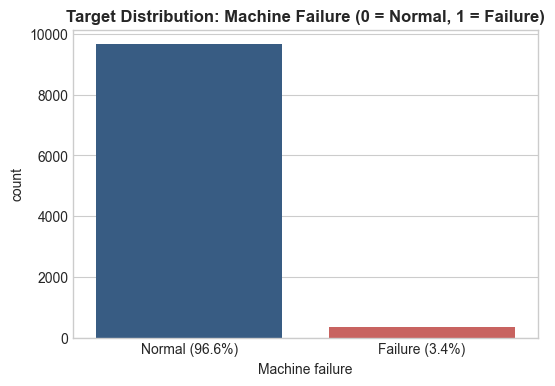

In [4]:
target_counts = df['Machine failure'].value_counts()
target_pct = df['Machine failure'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_pct.round(2)
})
print(target_summary)

# Visualization
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Machine failure', palette=['#2b5c8f', '#d9534f'], ax=ax)
ax.set_title("Target Distribution: Machine Failure (0 = Normal, 1 = Failure)", fontsize=12, fontweight='bold')
ax.set_xticklabels(['Normal (96.6%)', 'Failure (3.4%)'])
plt.show()

### 4. Failure Mode Analysis & The Target Leakage Warning

> **CRITICAL ARCHITECTURAL NOTE:**
> The columns `TWF` (Tool Wear Failure), `HDF` (Heat Dissipation Failure), `PWF` (Power Failure), `OSF` (Overstrain Failure), and `RNF` (Random Failure) describe the **root cause after a failure happens**.
>
> If we include these as input features when predicting `Machine failure`, our model will experience **100% Target Leakage** because in real deployment, an IoT sensor stream does not know which failure occurred before the machine breaks!

Failure Breakdown by Root Cause:
HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


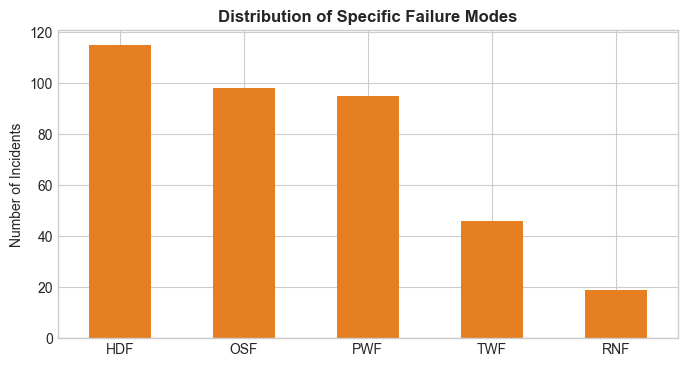

In [5]:
failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
failure_counts = df[failure_modes].sum().sort_values(ascending=False)

print("Failure Breakdown by Root Cause:")
print(failure_counts)

fig, ax = plt.subplots(figsize=(8, 4))
failure_counts.plot(kind='bar', color='#e67e22', ax=ax)
ax.set_title("Distribution of Specific Failure Modes", fontsize=12, fontweight='bold')
ax.set_ylabel("Number of Incidents")
plt.xticks(rotation=0)
plt.show()

### 5. Sensor Numerical Summaries & Distributions

Let's inspect the telemetry features available prior to failure:
- `Air temperature [K]`
- `Process temperature [K]`
- `Rotational speed [rpm]`
- `Torque [Nm]`
- `Tool wear [min]`

In [6]:
sensors = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

df[sensors].describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


C:\Users\surface\AppData\Local\Temp\ipykernel_2836\3601211852.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Machine failure', y=sensor, palette=['#3498db', '#e74c3c'], ax=axes[i])
C:\Users\surface\AppData\Local\Temp\ipykernel_2836\3601211852.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(['Normal', 'Failure'])
C:\Users\surface\AppData\Local\Temp\ipykernel_2836\3601211852.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Machine failure', y=sensor, palette=['#3498db', '#e74c3c'], ax=axes[i])
C:\Users\surface\AppData\Local\Temp\ipykernel_2836\360121

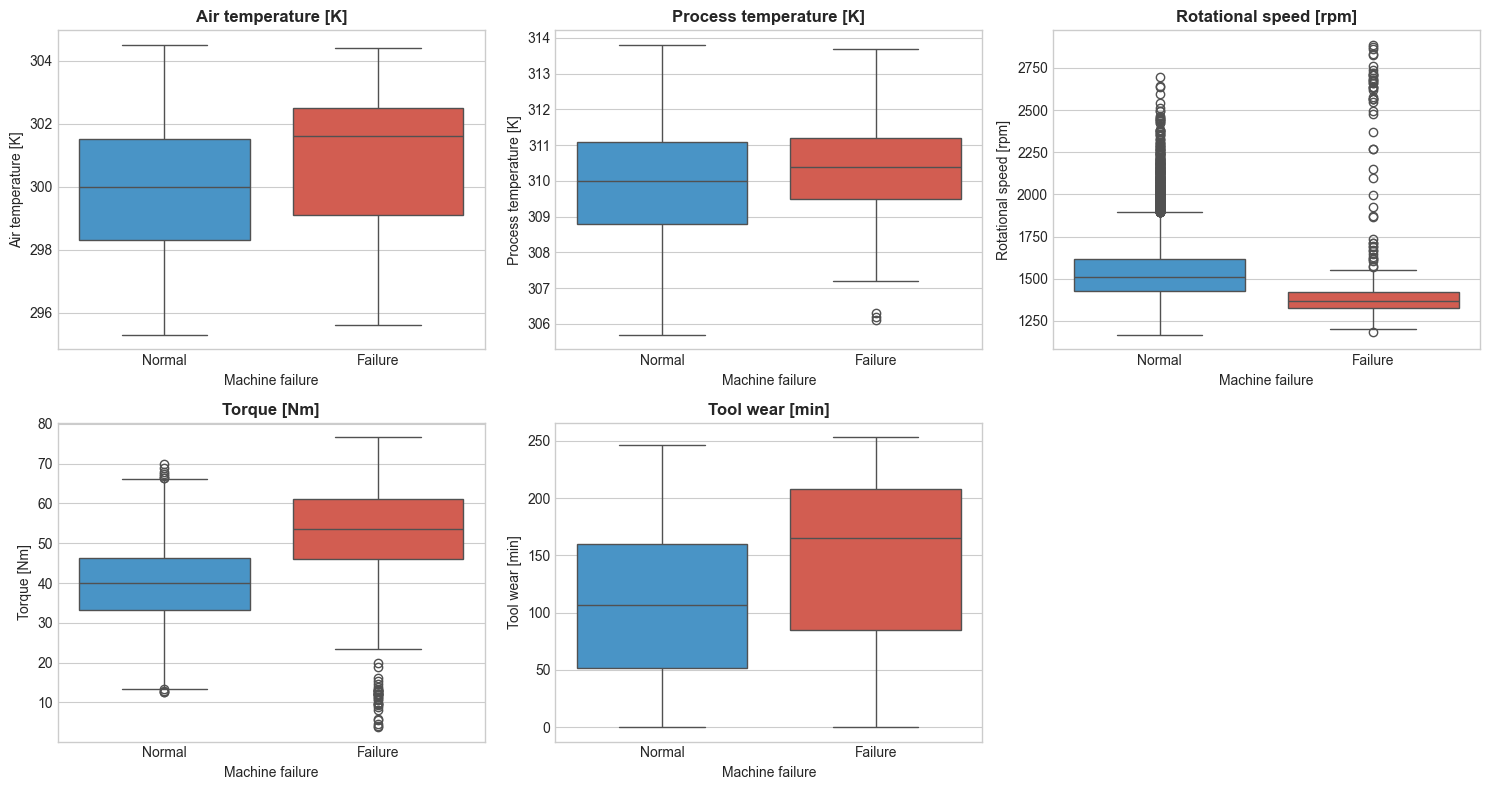

In [7]:
# Boxplots comparing sensors across normal vs failed states
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, sensor in enumerate(sensors):
    sns.boxplot(data=df, x='Machine failure', y=sensor, palette=['#3498db', '#e74c3c'], ax=axes[i])
    axes[i].set_title(sensor, fontweight='bold')
    axes[i].set_xticklabels(['Normal', 'Failure'])

# Hide the 6th unused subplot
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

### Key Takeaways from Day 1 EDA:
1. **Clean Data:** Zero missing values across 10,000 records.
2. **Severe Class Imbalance:** Exactly 339 failures (~3.39%) vs 9,661 normal operating instances (~96.61%). Raw accuracy is invalid as an evaluation metric.
3. **Target Leakage Identified:** `TWF`, `HDF`, `PWF`, `OSF`, `RNF` are post-mortem diagnostic flags and must be excluded from feature inputs $X$.
4. **Physics Clues:**
   - Failing machines exhibit markedly higher `Tool wear [min]`.
   - Failing machines exhibit extreme variance in `Torque [Nm]` and `Rotational speed [rpm]` (both very low and very high spikes).
   - `Process temperature` and `Air temperature` are closely coupled, hinting that their difference $(\Delta T)$ is a prime candidate for feature engineering on Day 2!